# 7. Comparación estadística

*Autores: María Carolina Cantillo Orozco (200179105) y Juan Camilo Oñoro Araujo (200177329)*

```{admonition} Qué responde este capítulo
:class: tip
**Pregunta.** De todas las diferencias observadas, ¿cuáles son reales y cuáles son ruido?

**Respuesta corta.** Friedman confirma que los modelos difieren. Con la mejor combinación de cada uno, el
XGBoost geográfico tiene el mejor rango medio, pero Nemenyi solo separa a Naive Bayes del grupo de cabeza.
Frente a la logística, el geográfico ordena mejor los estratos 1 a 4 y peor el 5 y el 6 (DeLong con Holm), con
un efecto pequeño (δ de Cliff = 0.28). En regresión, el MCS deja 8 de 28 combinaciones, y la diferencia entre
las dos mejores es significativa pero sin relevancia práctica.
```

Con 140 modelos hay 9 730 pares posibles; probarlos uno a uno con α = 0.05 daría unos 487 falsos positivos por
azar. Por eso la comparación es **jerárquica**: primero una prueba global, después comparaciones dirigidas entre
pocos finalistas con corrección por comparaciones múltiples, y siempre con tamaño del efecto.

## 7.1 Clasificación: Friedman → Nemenyi

**Bloques.** Con 5 pliegues externos, la prueba de Friedman tiene muy poca potencia (la diferencia crítica de
Nemenyi para 8 modelos sería de casi 5 rangos). Se usan además, como bloques, los **bloques espaciales de 2 km**
del Entregable 1: el F1 macro de las predicciones fuera de muestra de cada combinación, calculado en cada bloque.
Ambas versiones se reportan.

Todas las combinaciones, bloques = pliegues externos: χ²_F = 506.16, gl = 127, p = 1.04e-46, n = 5 bloques, diferencia crítica (Nemenyi, α = 0.05) = 103.42 rangos
Todas las combinaciones, bloques = bloques espaciales: χ²_F = 979.51, gl = 127, p = 1.23e-131, n = 32 bloques, diferencia crítica (Nemenyi, α = 0.05) = 40.88 rangos
Mejor combinación de cada modelo, bloques espaciales: χ²_F = 47.62, gl = 7, p = 4.22e-08, n = 32 bloques, diferencia crítica (Nemenyi, α = 0.05) = 1.86 rangos


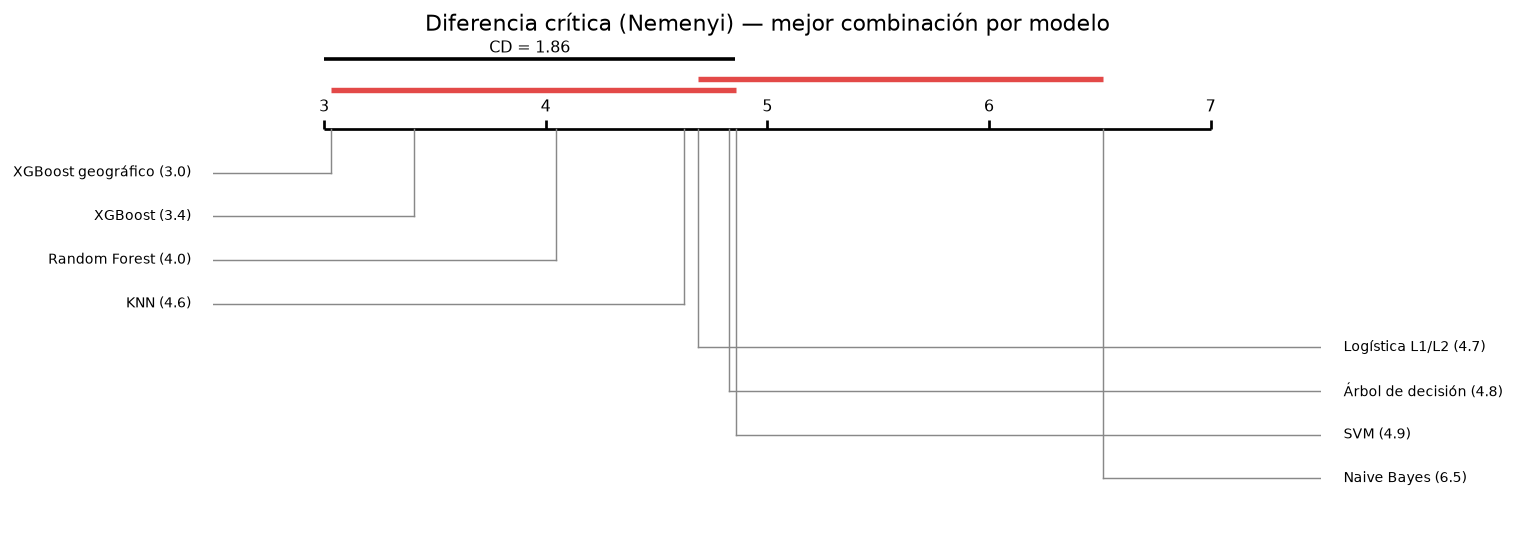

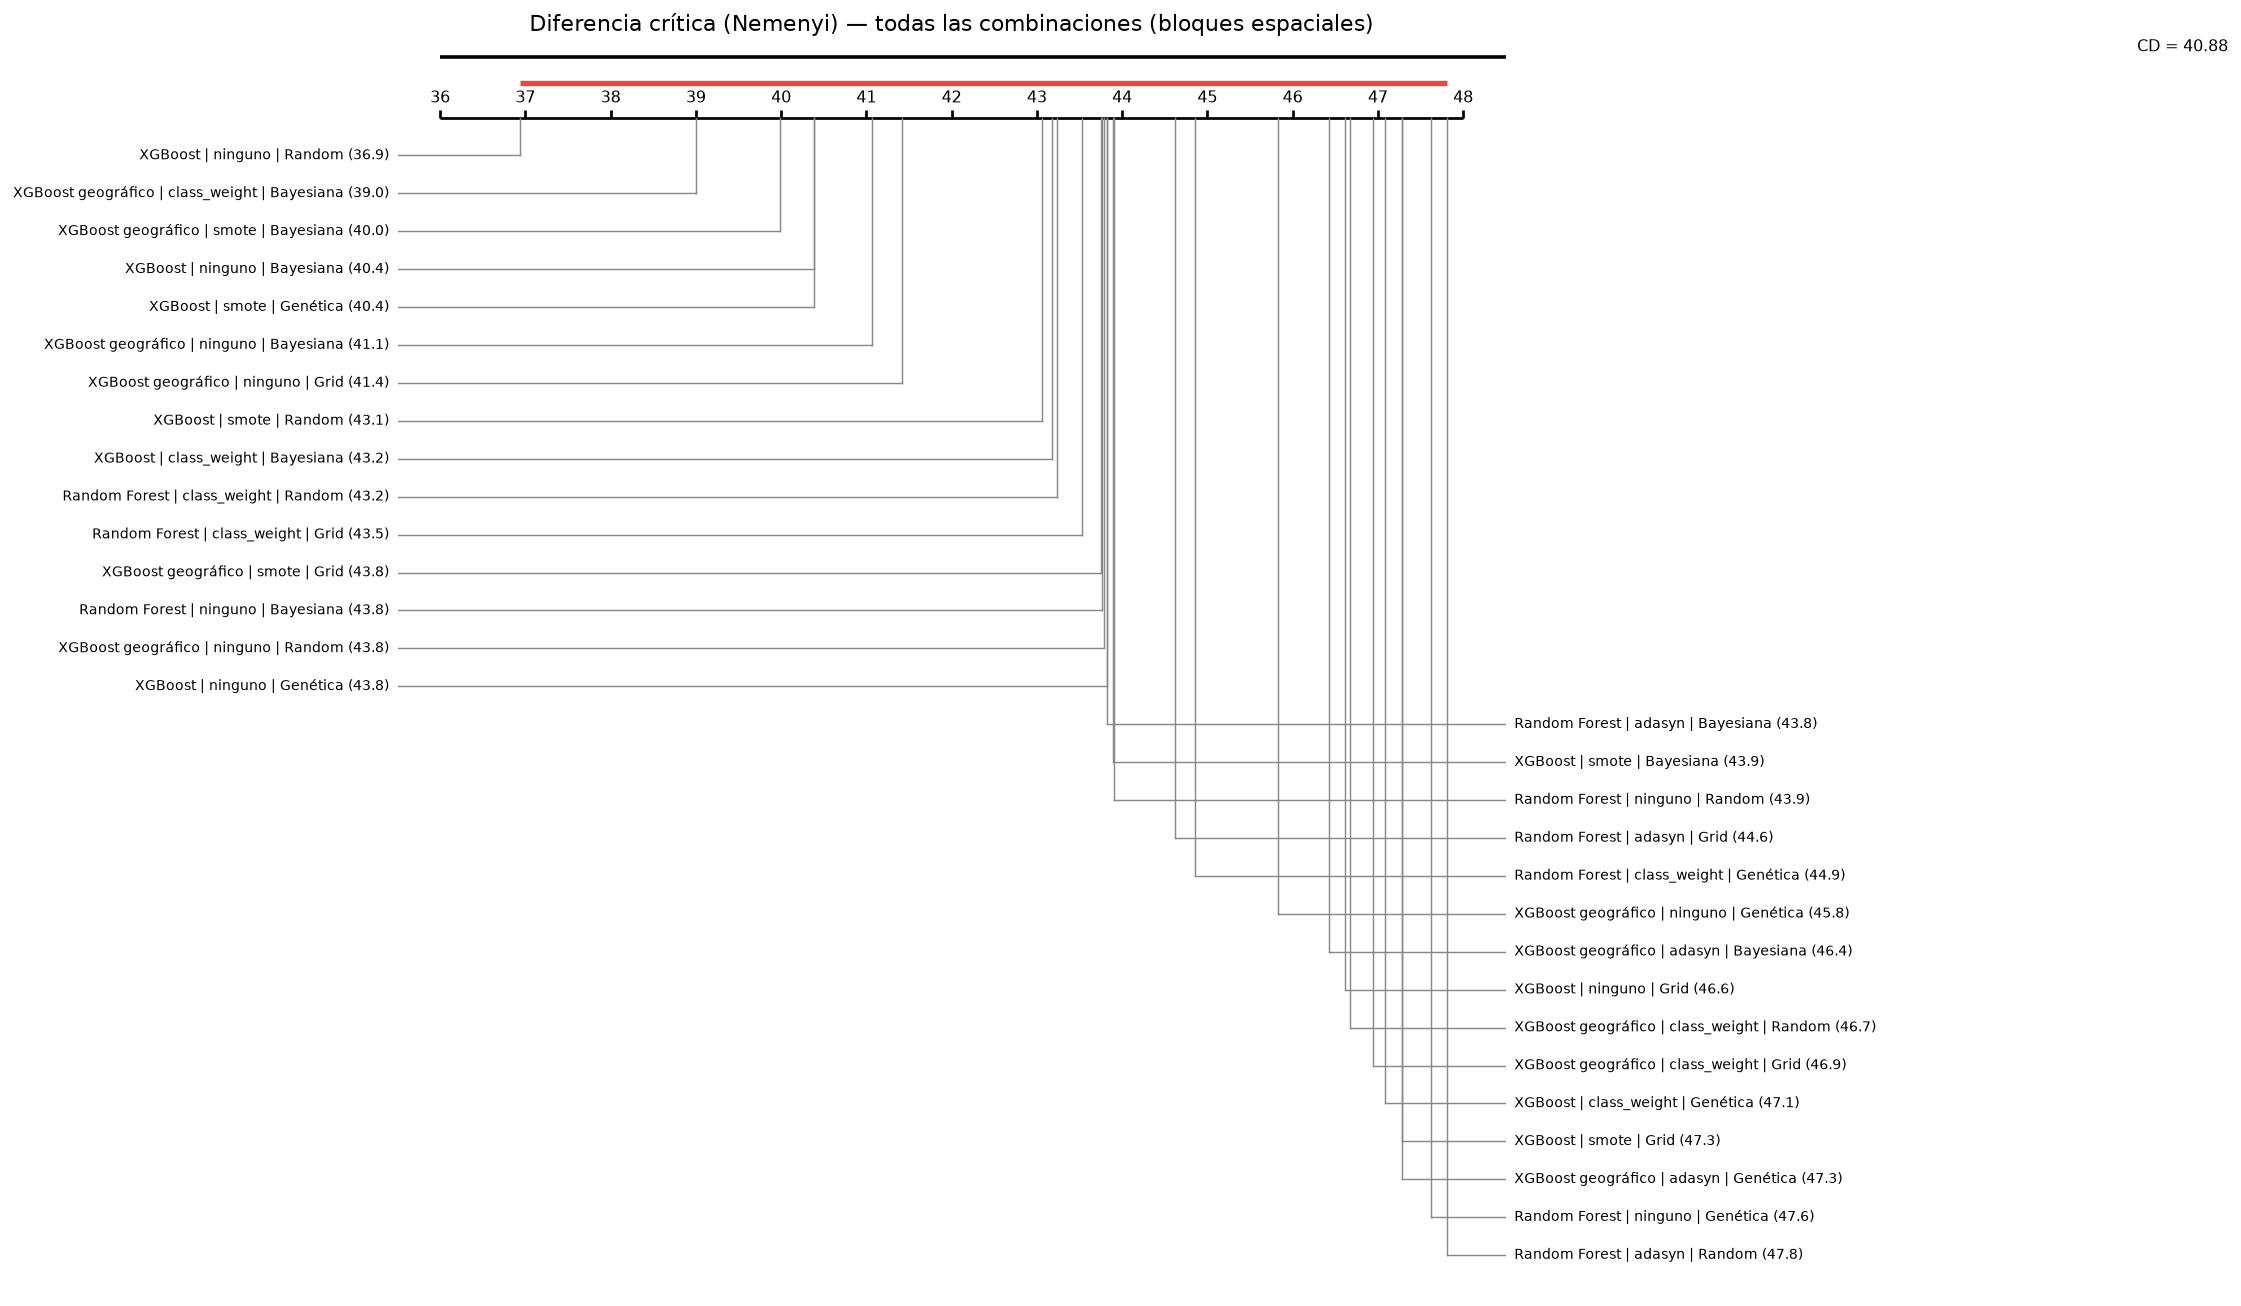

In [1]:
import pandas as pd

from _comun import figura, leer_json

A = leer_json("analisis_clasificacion.json") or {}
for clave, titulo in [("friedman_todas_pliegues", "Todas las combinaciones, bloques = pliegues externos"),
                      ("friedman_todas_bloques", "Todas las combinaciones, bloques = bloques espaciales"),
                      ("friedman_mejor_por_modelo", "Mejor combinación de cada modelo, bloques espaciales")]:
    if A.get(clave):
        f = A[clave]
        print(f"{titulo}: χ²_F = {f['chi2']:.2f}, gl = {f['gl']}, p = {f['p']:.3g}, n = {f['n_bloques']} bloques, "
              f"diferencia crítica (Nemenyi, α = 0.05) = {f['cd']:.2f} rangos")
figura("cd_mejor_combinación_por_modelo.png")
figura("cd_todas_las_combinaciones_(bloques_espaciales).png")

In [2]:
if A.get("nemenyi_mejor_por_modelo"):
    display(pd.DataFrame(A["nemenyi_mejor_por_modelo"]).round(3))

,Random Forest,XGBoost,XGBoost geográfico,SVM,Logística L1/L2,KNN,Árbol de decisión,Naive Bayes
Random Forest,1.000,0.967,0.714,0.889,0.967,0.982,0.908,0.001
XGBoost,0.967,1.000,0.999,0.255,0.420,0.488,0.281,0.000
XGBoost geográfico,0.714,0.999,1.000,0.057,0.121,0.155,0.066,0.000
SVM,0.889,0.255,0.057,1.000,1.000,1.000,1.000,0.121
Logística L1/L2,0.967,0.420,0.121,1.000,1.000,1.000,1.000,0.057
KNN,0.982,0.488,0.155,1.000,1.000,1.000,1.000,0.042
Árbol de decisión,0.908,0.281,0.066,1.000,1.000,1.000,1.000,0.106
Naive Bayes,0.001,0.000,0.000,0.121,0.057,0.042,0.106,1.000


**Lectura.** Las tres versiones de Friedman rechazan que todas las combinaciones sean equivalentes (p entre
10⁻⁴⁶ y 10⁻¹³¹). Con 128 combinaciones, sin embargo, la diferencia crítica es enorme (103 rangos con 5
pliegues; 41 con 32 bloques espaciales) y Nemenyi solo separa los extremos.

La comparación útil es la de la **mejor combinación de cada modelo** con 32 bloques espaciales (χ² = 47.6, p =
4·10⁻⁸, CD = 1.86 rangos). **El XGBoost geográfico tiene el mejor rango medio (3.03)**, seguido de XGBoost
(3.41) y Random Forest (4.05); KNN (4.63), la logística (4.69), el árbol (4.83) y SVM (4.86) forman un grupo
intermedio, y Naive Bayes es el último (6.52). En Nemenyi, lo único claramente separado es Naive Bayes, peor
que los tres ensambles y que KNN (p < 0.05). El XGBoost geográfico aventaja a la logística en 1.66 rangos,
menos que la CD (p = 0.12), y a SVM en 1.83 (p = 0.057). Nemenyi es conservador con 8 modelos; por eso las
comparaciones dirigidas de 7.2 y 7.3 se hacen solo entre finalistas.

## 7.2 Comparaciones dirigidas: DeLong con Holm

La prueba de DeLong compara dos AUC calculadas sobre las mismas observaciones teniendo en cuenta su correlación.
Es una prueba para AUC binarias, así que se aplica a cada estrato contra el resto (6 pruebas por par de
modelos), solo entre los tres mejores modelos y el modelo base, y los p-valores se ajustan con **Holm-Bonferroni**
(control del error familiar) y **Benjamini-Hochberg** (tasa de falsos descubrimientos).

In [3]:
if A.get("delong_finalistas"):
    dl = pd.DataFrame(A["delong_finalistas"])
    display(dl[["A", "B", "estrato", "auc_1", "auc_2", "diferencia", "z", "p", "p_holm", "p_bh"]].round(4))

,A,B,estrato,auc_1,auc_2,diferencia,z,p,p_holm,p_bh
0,Random Forest | smote | Genética,XGBoost | smote | Random,1,0.9412,0.9349,0.0063,5.3685,0.0000,0.0000,0.0000
1,Random Forest | smote | Genética,XGBoost | smote | Random,2,0.8927,0.8860,0.0067,3.7348,0.0002,0.0026,0.0003
2,Random Forest | smote | Genética,XGBoost | smote | Random,3,0.9192,0.9051,0.0140,8.6876,0.0000,0.0000,0.0000
3,Random Forest | smote | Genética,XGBoost | smote | Random,4,0.9506,0.9462,0.0045,2.7381,0.0062,0.0556,0.0079
4,Random Forest | smote | Genética,XGBoost | smote | Random,5,0.9555,0.9570,-0.0015,-1.0002,0.3172,1.0000,0.3460
5,Random Forest | smote | Genética,XGBoost | smote | Random,6,0.9717,0.9544,0.0173,4.7714,0.0000,0.0000,0.0000
6,Random Forest | smote | Genética,XGBoost geográfico | class_weight | Bayesiana,1,0.9412,0.9383,0.0029,2.3948,0.0166,0.1164,0.0200
7,Random Forest | smote | Genética,XGBoost geográfico | class_weight | Bayesiana,2,0.8927,0.8857,0.0070,3.6114,0.0003,0.0040,0.0005
8,Random Forest | smote | Genética,XGBoost geográfico | class_weight | Bayesiana,3,0.9192,0.8993,0.0198,8.7120,0.0000,0.0000,0.0000
9,Random Forest | smote | Genética,XGBoost geográfico | class_weight | Bayesiana,4,0.9506,0.9488,0.0018,1.2806,0.2003,1.0000,0.2254


**Lectura.** Las AUC se calculan con las predicciones fuera de muestra del bucle externo (10 001 viviendas),
así que diferencias pequeñas resultan significativas; lo que importa es el signo y el tamaño.

- **XGBoost geográfico frente a la logística** (la mejor combinación de la familia del modelo base): AUC mayor en
  los estratos 1 a 4 (+0.016 a +0.051, p de Holm < 10⁻⁴) y **menor en los estratos 5 y 6** (−0.019 y −0.011,
  también significativas).
- XGBoost y Random Forest muestran el mismo patrón frente a la logística: ganan en los estratos 1 a 4, empatan en
  el 5 y pierden en el 6. La logística ordena mejor los estratos altos; posiblemente porque son pocos, están
  concentrados y las variables físicas los separan casi linealmente, mientras que los estratos bajos y medios se
  mezclan en el espacio y ahí ayudan las interacciones de los árboles.
- Entre ensambles las diferencias son de milésimas y cambian de signo según el estrato. Random Forest ordena algo
  mejor que los dos XGBoost en la mayoría de estratos; el XGBoost geográfico supera al global en los estratos 1 y
  6 (y en el 4 sin significancia tras Holm) y pierde en el 3 y el 5.

Una AUC por estrato mide la capacidad de **ordenar**; el F1 macro mide la decisión final. Por eso Random
Forest puede tener AUC algo mayores y aun así quedar detrás del XGBoost geográfico en el rango de F1 por
bloques.

## 7.3 Tamaño del efecto e intervalos de confianza

**Delta de Cliff** (sobre el F1 por bloque espacial): probabilidad de que un modelo supere al otro en un bloque
menos la probabilidad contraria; |δ| < 0.147 despreciable, < 0.33 pequeño, < 0.474 mediano, mayor grande.
**Intervalos BCa** (*bias-corrected and accelerated*) del F1 macro, remuestreando bloques espaciales completos.

In [4]:
if A.get("cliff_finalistas"):
    display(pd.DataFrame(A["cliff_finalistas"]).round(3))
if A.get("ic_bca_f1_finalistas"):
    display(pd.DataFrame(A["ic_bca_f1_finalistas"], index=["IC 95 % inf", "IC 95 % sup"]).T.round(3))

,A,B,delta_cliff_bloques,magnitud
0,Random Forest | smote | Genética,XGBoost | smote | Random,-0.093,despreciable
1,Random Forest | smote | Genética,XGBoost geográfico | class_weight | Bayesiana,-0.128,despreciable
2,Random Forest | smote | Genética,Logística L1/L2 | ninguno | Bayesiana,0.172,pequeño
3,XGBoost | smote | Random,XGBoost geográfico | class_weight | Bayesiana,-0.038,despreciable
4,XGBoost | smote | Random,Logística L1/L2 | ninguno | Bayesiana,0.242,pequeño
5,XGBoost geográfico | class_weight | Bayesiana,Logística L1/L2 | ninguno | Bayesiana,0.283,pequeño


,IC 95 % inf,IC 95 % sup
Random Forest | smote | Genética,0.640,0.728
XGBoost | smote | Random,0.654,0.729
XGBoost geográfico | class_weight | Bayesiana,0.648,0.732
Logística L1/L2 | ninguno | Bayesiana,0.584,0.691


**Lectura.** Los intervalos BCa del F1 macro (remuestreando bloques espaciales) se solapan entre los tres
ensambles: Random Forest [0.640, 0.728], XGBoost [0.654, 0.729] y XGBoost geográfico [0.648, 0.732]. El de la
logística, [0.584, 0.691], está desplazado hacia abajo, aunque se solapa en parte con los demás.

El delta de Cliff confirma la lectura. Entre ensambles es despreciable (|δ| ≤ 0.13). Frente a la logística es
**pequeño y a favor de los ensambles**, mayor para el XGBoost geográfico (δ = 0.28: sin empates, gana en ≈ 64
% de los pares de bloques y pierde en ≈ 36 %) que para XGBoost (0.24) y Random Forest (0.17).

**Conclusión de la comparación en zonas nuevas:** el XGBoost geográfico está en el grupo de los mejores, sin
diferencia demostrable con XGBoost y Random Forest, y mejora a la logística con un efecto pequeño pero
consistente en las tres miradas (rango, AUC de los estratos 1–4 y delta de Cliff).

## 7.4 Regresión: MCS → Giacomini-White / Clark-West → Diebold-Mariano

- **Model Confidence Set** (Hansen, Lunde y Nason, 2011): parte de las 28 combinaciones y elimina, con bootstrap
  por bloques, las significativamente peores; quedan las indistinguibles de la mejor (α = 0.10).
- **Giacomini-White** (2006) entre finalistas no anidados: ¿un modelo es mejor de forma condicional (dada la
  diferencia de pérdida de la vivienda vecina en el orden sur → norte)?
- **Clark-West** (2007) para un par **anidado**: Ridge con vecindad física frente a Ridge sin ella. Corrige el
  sesgo del Diebold-Mariano a favor del modelo grande.
- **Diebold-Mariano** con la corrección de Harvey, Leybourne y Newbold entre el mejor y el segundo, con intervalo
  por **bootstrap estacionario** (Politis y Romano, 1994) y d de Cohen.

In [5]:
AR = leer_json("analisis_regresion.json") or {}
if AR.get("mcs"):
    display(pd.DataFrame(AR["mcs"]).round(4))
if AR.get("giacomini_white"):
    display(pd.DataFrame(AR["giacomini_white"]).round(4))
for k in ["clark_west_ridge_vecindad", "diebold_mariano_hln"]:
    if AR.get(k):
        print(k, AR[k])

,Model name,Pvalue,en_el_conjunto,perdida_media,rango_perdida
0,Random Forest (regresión) | Grid,1.0000,True,0.3361,12.9538
1,Random Forest (regresión) | Random,0.2773,True,0.3457,12.9360
2,Random Forest (regresión) | Genética,0.2362,True,0.3471,12.8802
3,XGBoost (regresión) | Random,0.4635,True,0.3482,13.5731
4,XGBoost (regresión) | Bayesiana,0.2773,True,0.3513,13.5262
5,XGBoost (regresión) | Genética,0.0711,False,0.3567,13.3256
6,SVR | Random,0.4785,True,0.3593,14.0688
7,SVR | Grid,0.4785,True,0.3616,13.9522
8,SVR | Bayesiana,0.4785,True,0.3627,14.4429
9,Random Forest (regresión) | Bayesiana,0.0621,False,0.3657,12.8231


,A,B,estadistico,gl,p,signo
0,Random Forest (regresión) | Grid,Random Forest (regresión) | Random,207.1860,2,0.0,modelo 1 mejor
1,Random Forest (regresión) | Grid,Random Forest (regresión) | Genética,176.9032,2,0.0,modelo 1 mejor
2,Random Forest (regresión) | Grid,XGBoost (regresión) | Random,439.9519,2,0.0,modelo 1 mejor
3,Random Forest (regresión) | Random,Random Forest (regresión) | Genética,82.2043,2,0.0,modelo 1 mejor
4,Random Forest (regresión) | Random,XGBoost (regresión) | Random,307.3110,2,0.0,modelo 1 mejor
5,Random Forest (regresión) | Genética,XGBoost (regresión) | Random,307.9129,2,0.0,modelo 1 mejor


clark_west_ridge_vecindad {'alpha': 141.7710381103998, 'media_ajustada': 0.5860443668108442, 'estadistico': 47.352146203861885, 'p_una_cola': 0.0}
diebold_mariano_hln {'mejor': 'Random Forest (regresión) | Grid', 'segundo': 'Random Forest (regresión) | Random', 'diferencia_perdida': -0.009638045279607078, 'estadistico': -5.665901363064036, 'p': 1.5030012747987353e-08, 'ic95_bootstrap_estacionario': [-0.01921152126966127, -0.0012228799866175095], 'd_cohen': -0.056656180892412415}


**Lectura.** El MCS (α = 0.10) conserva 8 de las 28 combinaciones: Random Forest con Grid, Random y Genética,
XGBoost con Random y Bayesiana, y SVR con Random, Grid y Bayesiana; elimina KNN, los lineales y el árbol.

Giacomini-White distingue a los finalistas de forma condicional (p < 10⁻¹⁸ en los 6 pares, siempre a favor del
de menor pérdida media): conociendo la diferencia de pérdida de la vivienda vecina se puede anticipar cuál
modelo se equivocará menos, otra vez porque los errores están correlacionados en el espacio. Con 10 001
viviendas, además, la prueba detecta diferencias muy pequeñas.

Diebold-Mariano (HLN) entre los dos primeros (Random Forest con Grid y con Random) encuentra una diferencia
estadísticamente significativa (−0.0096 en pérdida cuadrática, p = 1.5·10⁻⁸; IC 95 % por bootstrap
estacionario [−0.019, −0.001]) pero **sin relevancia práctica**: d de Cohen = −0.06.

Clark-West confirma que la vecindad física aporta información: Ridge con las 7 variables de vecindad predice
mejor que el mismo Ridge sin ellas (estadístico 47.4, p ≈ 0).